In [ ]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler

In [ ]:
flights=sns.load_dataset("flights")
import seaborn as sns

In [ ]:
passengers=flights["passengers"]
passengers.head()



,passengers
0,112
1,118
2,132
3,129
4,121


In [ ]:
data=passengers.values
print(data)

[112 118 132 129 121 135 148 148 136 119 104 118 115 126 141 135 125 149
 170 170 158 133 114 140 145 150 178 163 172 178 199 199 184 162 146 166
 171 180 193 181 183 218 230 242 209 191 172 194 196 196 236 235 229 243
 264 272 237 211 180 201 204 188 235 227 234 264 302 293 259 229 203 229
 242 233 267 269 270 315 364 347 312 274 237 278 284 277 317 313 318 374
 413 405 355 306 271 306 315 301 356 348 355 422 465 467 404 347 305 336
 340 318 362 348 363 435 491 505 404 359 310 337 360 342 406 396 420 472
 548 559 463 407 362 405 417 391 419 461 472 535 622 606 508 461 390 432]


In [ ]:
type(data)

numpy.ndarray

In [ ]:
print(data.shape)

(144,)


In [ ]:
data=data.reshape(-1,1)
print(data.shape)

(144, 1)


In [ ]:
print(type(data))
print(data.shape)
print(data[:5])

<class 'numpy.ndarray'>
(144, 1)
[[112]
 [118]
 [132]
 [129]
 [121]]


In [ ]:
print(data.dtype)

int64


In [ ]:
data=data.astype(np.float32)
print(data.dtype)

float32


In [ ]:
scaler=MinMaxScaler(feature_range=(0,1))
scaled_data=scaler.fit_transform(data)

In [ ]:
print(scaled_data[:10])

[[0.01544401]
 [0.02702703]
 [0.05405405]
 [0.04826255]
 [0.03281853]
 [0.05984557]
 [0.08494207]
 [0.08494207]
 [0.06177607]
 [0.02895753]]


In [ ]:
sequence_length=3
x=[]
y=[]
for i in range(len(scaled_data)-sequence_length):
  x.append(scaled_data[i:i+sequence_length])
  y.append(scaled_data[i+sequence_length])


In [ ]:
x=np.array(x)
y=np.array(y)

In [ ]:
print(x.shape)
print(y.shape)

(141, 3, 1)
(141, 1)


In [ ]:
x=torch.tensor(x, dtype=torch.float32)
y=torch.tensor(y, dtype=torch.float32)

In [ ]:
print(x.shape)
print(y.shape)

torch.Size([141, 3, 1])
torch.Size([141, 1])


In [ ]:
import torch
X=torch.tensor([10.0])
w=torch.tensor([2.0], requires_grad=True)
b=torch.tensor([1.0], requires_grad=True)
Y=x*w+b
print(Y)

tensor([[[1.0309],
         [1.0541],
         [1.1081]],

        [[1.0541],
         [1.1081],
         [1.0965]],

        [[1.1081],
         [1.0965],
         [1.0656]],

        [[1.0965],
         [1.0656],
         [1.1197]],

        [[1.0656],
         [1.1197],
         [1.1699]],

        [[1.1197],
         [1.1699],
         [1.1699]],

        [[1.1699],
         [1.1699],
         [1.1236]],

        [[1.1699],
         [1.1236],
         [1.0579]],

        [[1.1236],
         [1.0579],
         [1.0000]],

        [[1.0579],
         [1.0000],
         [1.0541]],

        [[1.0000],
         [1.0541],
         [1.0425]],

        [[1.0541],
         [1.0425],
         [1.0849]],

        [[1.0425],
         [1.0849],
         [1.1429]],

        [[1.0849],
         [1.1429],
         [1.1197]],

        [[1.1429],
         [1.1197],
         [1.0811]],

        [[1.1197],
         [1.0811],
         [1.1737]],

        [[1.0811],
         [1.1737],
         [1.2548]]

In [ ]:
import torch
X=torch.tensor([10.0])
target=torch.tensor([30.0])
w=torch.tensor([2.0],requires_grad=True)
b=torch.tensor([1.0],requires_grad=True)
prediction=X*w+b
loss=(prediction-target)**2
print("Prediction:", prediction.item())
print("Target:",target.item())
print("Loss", loss.item())
loss.backward()
print("Gradient of weight", w.grad)
print("Gradient of bias", b.grad)

Prediction: 21.0
Target: 30.0
Loss 81.0
Gradient of weight tensor([-180.])
Gradient of bias tensor([-18.])


In [ ]:
learning_rate=0.01
with torch.no_grad():
  w-=learning_rate * w.grad
  b-=learning_rate * b.grad
  print("updated weights",w)
  print("updates bias", b)


updated weights tensor([3.8000], requires_grad=True)
updates bias tensor([1.1800], requires_grad=True)


In [ ]:
print(w.grad)

tensor([-180.])


In [ ]:
w.grad.zero_()
b.grad.zero_()


tensor([0.])

In [ ]:
#matrix multiplication
import torch
W=torch.tensor([[1.0,2.0],
                [3.0,4.0]])
print("matrix W")
print(W)
print("\nShape:", W.shape)

matrix W
tensor([[1., 2.],
        [3., 4.]])

Shape: torch.Size([2, 2])


In [ ]:
## Column Vectors
##In LSTMs, inputs and hidden states are usually represented as column vectors before matrix multiplication.
X=torch.tensor([[5.0],
                [6.0]])
print("Column Vector x:")
print(X)
print("\nShape:",X.shape)

Column Vector x:
tensor([[5.],
        [6.]])

Shape: torch.Size([2, 1])


In [ ]:
## Matrix × Column Vector
##Now we'll multiply a matrix with a column vector.
##This is the same operation used inside every LSTM gate.
##We will first let PyTorch compute it, then we'll verify the answer manually.
W=torch.tensor([[1.0,2.0],
                [3.0,4.0]])
X=torch.tensor([[5.0],
                [6.0]])
Y=torch.matmul(W,X)
print("Output:")
print(Y)
print("\nshape:",Y.shape)



Output:
tensor([[17.],
        [39.]])

shape: torch.Size([2, 1])


In [ ]:
# Model Hyperparameters

input_size = 1      # One feature: passenger count
hidden_size = 16    # Number of memory units
output_size = 1     # Predict one value


In [ ]:
# Forget Gate Parameters

Wf = torch.randn(hidden_size, input_size, requires_grad=True)
Uf = torch.randn(hidden_size, hidden_size, requires_grad=True)
bf = torch.zeros(hidden_size, 1, requires_grad=True)

# Input Gate Parameters

Wi = torch.randn(hidden_size, input_size, requires_grad=True)
Ui = torch.randn(hidden_size, hidden_size, requires_grad=True)
bi = torch.zeros(hidden_size, 1, requires_grad=True)

# Candidate Memory Parameters

Wc = torch.randn(hidden_size, input_size, requires_grad=True)
Uc = torch.randn(hidden_size, hidden_size, requires_grad=True)
bc = torch.zeros(hidden_size, 1, requires_grad=True)

# Output Gate Parameters

Wo = torch.randn(hidden_size, input_size, requires_grad=True)
Uo = torch.randn(hidden_size, hidden_size, requires_grad=True)
bo = torch.zeros(hidden_size, 1, requires_grad=True)

# Final Output Layer

Wy = torch.randn(output_size, hidden_size, requires_grad=True)
by = torch.zeros(output_size, 1, requires_grad=True)


In [ ]:
print(x.shape)
print(y.shape)


torch.Size([141, 3, 1])
torch.Size([141, 1])


In [ ]:
sample=x[0]
print("Sequence")
print(sample)
print("\nShape:",sample.shape)

Sequence
tensor([[0.0154],
        [0.0270],
        [0.0541]])

Shape: torch.Size([3, 1])


In [ ]:
# Current timestep (t = 0)
x_t = sample[0].reshape(input_size, 1)
print("Current Input:")
print(x_t)
print("\nShape:", x_t.shape)


Current Input:
tensor([[0.0154]])

Shape: torch.Size([1, 1])


In [ ]:
h_prev=torch.zeros(hidden_size,1)
print(h_prev.shape)

torch.Size([16, 1])


In [ ]:
c_prev=torch.zeros(hidden_size,1)
print(c_prev.shape)

torch.Size([16, 1])


In [ ]:
# Forget Gate

#The forget gate decides how much information from the previous cell state should be kept.

#Equation:

#fₜ = σ(Wf·xₜ + Uf·hₜ₋₁ + bf)

forget_linear=Wf@x_t + Uf@h_prev +bf
print(forget_linear.shape)
print(forget_linear)
f_t = torch.sigmoid(Wf@x_t + Uf@h_prev + bf)

torch.Size([16, 1])
tensor([[-0.0109],
        [-0.0183],
        [-0.0067],
        [-0.0119],
        [-0.0095],
        [ 0.0195],
        [-0.0084],
        [ 0.0120],
        [ 0.0008],
        [-0.0159],
        [ 0.0038],
        [-0.0066],
        [-0.0061],
        [-0.0125],
        [ 0.0094],
        [-0.0054]], grad_fn=<AddBackward0>)


In [ ]:
input_linear = Wi@x_t + Ui@h_prev + bi

print("Shape:", input_linear.shape)
print(input_linear)
i_t=torch.sigmoid(input_linear)

Shape: torch.Size([16, 1])
tensor([[-0.0059],
        [-0.0062],
        [ 0.0032],
        [ 0.0120],
        [ 0.0291],
        [ 0.0066],
        [ 0.0015],
        [ 0.0013],
        [-0.0025],
        [-0.0080],
        [-0.0212],
        [-0.0114],
        [ 0.0182],
        [ 0.0032],
        [ 0.0065],
        [ 0.0009]], grad_fn=<AddBackward0>)


In [ ]:
candidate_linear = Wc@x_t + Uc@h_prev + bc
print("Shape:", candidate_linear.shape)
print(candidate_linear)
c_candidate = torch.tanh(candidate_linear)
print("Shape:", c_candidate.shape)
print(c_candidate)

Shape: torch.Size([16, 1])
tensor([[ 0.0098],
        [-0.0081],
        [ 0.0146],
        [ 0.0140],
        [-0.0330],
        [ 0.0026],
        [ 0.0053],
        [-0.0148],
        [ 0.0093],
        [-0.0128],
        [-0.0313],
        [-0.0189],
        [ 0.0104],
        [-0.0025],
        [-0.0265],
        [ 0.0119]], grad_fn=<AddBackward0>)
Shape: torch.Size([16, 1])
tensor([[ 0.0098],
        [-0.0081],
        [ 0.0146],
        [ 0.0140],
        [-0.0330],
        [ 0.0026],
        [ 0.0053],
        [-0.0148],
        [ 0.0093],
        [-0.0128],
        [-0.0312],
        [-0.0189],
        [ 0.0104],
        [-0.0025],
        [-0.0265],
        [ 0.0119]], grad_fn=<TanhBackward0>)


In [ ]:
# Cell State Update
# This is the main memory update equation of an LSTM.
old_memory = f_t * c_prev
print(old_memory.shape)
print(old_memory)

torch.Size([16, 1])
tensor([[0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.]], grad_fn=<MulBackward0>)


In [ ]:
# Output Gate

# The output gate decides how much of the updated cell state should be exposed as the hidden state.
output_linear = Wo@x_t + Uo@h_prev + bo
print(output_linear.shape)
print(output_linear)
o_t = torch.sigmoid(output_linear)
print(o_t.shape)
print(o_t)



torch.Size([16, 1])
tensor([[-0.0089],
        [-0.0081],
        [ 0.0181],
        [-0.0033],
        [-0.0079],
        [ 0.0243],
        [-0.0092],
        [-0.0186],
        [-0.0313],
        [-0.0067],
        [ 0.0142],
        [ 0.0002],
        [ 0.0268],
        [ 0.0048],
        [-0.0059],
        [-0.0083]], grad_fn=<AddBackward0>)
torch.Size([16, 1])
tensor([[0.4978],
        [0.4980],
        [0.5045],
        [0.4992],
        [0.4980],
        [0.5061],
        [0.4977],
        [0.4954],
        [0.4922],
        [0.4983],
        [0.5036],
        [0.5001],
        [0.5067],
        [0.5012],
        [0.4985],
        [0.4979]], grad_fn=<SigmoidBackward0>)


In [ ]:
old_memory = f_t * c_prev
new_memory = i_t * c_candidate
c_t = old_memory + new_memory

In [ ]:
# Hidden State

#The hidden state is the final output of the LSTM cell.

cell_output = torch.tanh(c_t)
print(cell_output.shape)
print(cell_output)
h_t = o_t * cell_output
print(h_t.shape)
print(h_t)

torch.Size([16, 1])
tensor([[ 0.0049],
        [-0.0040],
        [ 0.0073],
        [ 0.0071],
        [-0.0167],
        [ 0.0013],
        [ 0.0026],
        [-0.0074],
        [ 0.0046],
        [-0.0064],
        [-0.0155],
        [-0.0094],
        [ 0.0052],
        [-0.0013],
        [-0.0133],
        [ 0.0059]], grad_fn=<TanhBackward0>)
torch.Size([16, 1])
tensor([[ 0.0024],
        [-0.0020],
        [ 0.0037],
        [ 0.0035],
        [-0.0083],
        [ 0.0007],
        [ 0.0013],
        [-0.0037],
        [ 0.0023],
        [-0.0032],
        [-0.0078],
        [-0.0047],
        [ 0.0026],
        [-0.0006],
        [-0.0066],
        [ 0.0030]], grad_fn=<MulBackward0>)


In [ ]:
#LSTM Cell Function

#nstead of writing every gate separately for each timestep, we combine all the equations into one function.
def lstm_cell(x_t, h_prev, c_prev):
  # Forget Gate
    f_t = torch.sigmoid(Wf @ x_t + Uf @ h_prev + bf)
    # Input Gate
    i_t = torch.sigmoid(Wi @ x_t + Ui @ h_prev + bi)

    # Candidate Cell State
    c_candidate = torch.tanh(Wc @ x_t + Uc @ h_prev + bc)

    # Update Cell State
    c_t = f_t * c_prev + i_t * c_candidate

    # Output Gate
    o_t = torch.sigmoid(Wo @ x_t + Uo @ h_prev + bo)
    # Hidden State
    h_t = o_t * torch.tanh(c_t)

    return h_t, c_t


In [ ]:
h_new, c_new = lstm_cell(x_t, h_prev, c_prev)

print("Hidden State Shape:", h_new.shape)
print("Cell State Shape:", c_new.shape)

Hidden State Shape: torch.Size([16, 1])
Cell State Shape: torch.Size([16, 1])


In [ ]:
# Process One Sequence
# Instead of processing only one timestep, we now process an entire sequence.
#For every timestep:
#1. Pass the current input to the LSTM cell.
#2. Get the new hidden state and cell state.
#3. Use them for the next timestep.
# Initialize hidden state and cell state
h_prev = torch.zeros(hidden_size, 1)
c_prev = torch.zeros(hidden_size, 1)

# Take the first training sequence
sample = x[0]
print(sample.shape)
print(sample)

torch.Size([3, 1])
tensor([[0.0154],
        [0.0270],
        [0.0541]])


In [ ]:
for t in range(sequence_length):
  # Current timestep input
    x_t = sample[t].reshape(input_size, 1)
    # Forward pass through one LSTM cell
    h_prev, c_prev = lstm_cell(x_t, h_prev, c_prev)

    print(f"Time Step {t+1}")
    print("Input:", x_t.item())
    print("Hidden State Shape:", h_prev.shape)
    print("Cell State Shape:", c_prev.shape)
    print("-" * 30)

Time Step 1
Input: 0.015444010496139526
Hidden State Shape: torch.Size([16, 1])
Cell State Shape: torch.Size([16, 1])
------------------------------
Time Step 2
Input: 0.027027025818824768
Hidden State Shape: torch.Size([16, 1])
Cell State Shape: torch.Size([16, 1])
------------------------------
Time Step 3
Input: 0.054054051637649536
Hidden State Shape: torch.Size([16, 1])
Cell State Shape: torch.Size([16, 1])
------------------------------


In [ ]:
# Output Layer
Wy = torch.randn(output_size, hidden_size, requires_grad=True)
by = torch.zeros(output_size, 1, requires_grad=True)
print("Wy Shape:", Wy.shape)
print("by Shape:", by.shape)

Wy Shape: torch.Size([1, 16])
by Shape: torch.Size([1, 1])


In [ ]:
prediction = Wy @ h_prev + by
print("Prediction Shape:", prediction.shape)
print(prediction)

Prediction Shape: torch.Size([1, 1])
tensor([[-0.0192]], grad_fn=<AddBackward0>)


In [ ]:
# Target Value
target = y[0].reshape(output_size, 1)

print(target)
print(target.shape)

tensor([[0.0483]])
torch.Size([1, 1])


In [ ]:
# Mean Squared Error
loss = (prediction - target) ** 2
print(loss)

tensor([[0.0046]], grad_fn=<PowBackward0>)


In [ ]:
loss = loss.mean()
print(loss)

tensor(0.0046, grad_fn=<MeanBackward0>)


In [ ]:
loss.backward()
print(Wf.grad.shape)
print(Wf.grad)

torch.Size([16, 1])
tensor([[ 4.3089e-05],
        [ 2.8071e-05],
        [-4.8096e-05],
        [ 8.4823e-05],
        [ 2.6422e-06],
        [-1.8631e-04],
        [ 5.5855e-06],
        [ 4.9747e-06],
        [-7.0171e-05],
        [-4.2796e-05],
        [ 7.0662e-06],
        [-1.3884e-04],
        [ 3.1910e-04],
        [ 3.3378e-05],
        [ 5.8923e-05],
        [ 5.1653e-06]])


In [ ]:
optimizer = torch.optim.Adam(
    [
        Wf, Uf, bf,
        Wi, Ui, bi,
        Wc, Uc, bc,
        Wo, Uo, bo,
        Wy, by
    ],
    lr=0.01
)

In [ ]:
optimizer.zero_grad()

In [ ]:
epochs = 200
losses = []

for epoch in range(epochs):

    total_loss = 0

    # Loop through all training sequences
    for idx in range(len(x)):

        # Reset gradients
        optimizer.zero_grad()

        # Initialize hidden state and cell state
        h_prev = torch.zeros(hidden_size, 1)
        c_prev = torch.zeros(hidden_size, 1)

        # Current training sequence
        sample = x[idx]

        # Pass all timesteps through the LSTM
        for t in range(sequence_length):
            x_t = sample[t].reshape(input_size, 1)
            h_prev, c_prev = lstm_cell(x_t, h_prev, c_prev)

        # Predict next value
        prediction = Wy @ h_prev + by

        # True target
        target = y[idx].reshape(output_size, 1)

        # Mean Squared Error
        loss = ((prediction - target) ** 2).mean()

        # Backpropagation
        loss.backward()

        # Update parameters
        optimizer.step()

        total_loss += loss.item()

    avg_loss = total_loss / len(x)
    losses.append(avg_loss)

    if epoch % 20 == 0:
        print(f"Epoch {epoch}: Loss = {avg_loss:.6f}")

print("Training complete!")

Epoch 0: Loss = 0.009010
Epoch 20: Loss = 0.003801
Epoch 40: Loss = 0.003636
Epoch 60: Loss = 0.003553
Epoch 80: Loss = 0.003518
Epoch 100: Loss = 0.003314
Epoch 120: Loss = 0.003166
Epoch 140: Loss = 0.003046
Epoch 160: Loss = 0.002998
Epoch 180: Loss = 0.002948
Training complete!


In [ ]:
predictions = []

with torch.no_grad():

    for idx in range(len(x)):

        # Reset hidden state and cell state
        h_prev = torch.zeros(hidden_size, 1)
        c_prev = torch.zeros(hidden_size, 1)

        sample = x[idx]

        # Process the sequence
        for t in range(sequence_length):
            x_t = sample[t].reshape(input_size, 1)
            h_prev, c_prev = lstm_cell(x_t, h_prev, c_prev)

        # Predict next passenger value
        prediction = Wy @ h_prev + by

        predictions.append(prediction.item())

In [ ]:
# Inverse Transform
# Convert predictions to NumPy array
predictions = np.array(predictions).reshape(-1, 1)

# Convert back to original scale
predictions = scaler.inverse_transform(predictions)

# Convert actual values back to original scale
actual = scaler.inverse_transform(y.numpy())

print("First 5 Predictions:")
print(predictions[:5])

print("\nFirst 5 Actual Values:")
print(actual[:5])

First 5 Predictions:
[[164.81615979]
 [160.90607732]
 [155.55710216]
 [171.10344792]
 [180.66554571]]

First 5 Actual Values:
[[129.]
 [121.]
 [135.]
 [148.]
 [148.]]


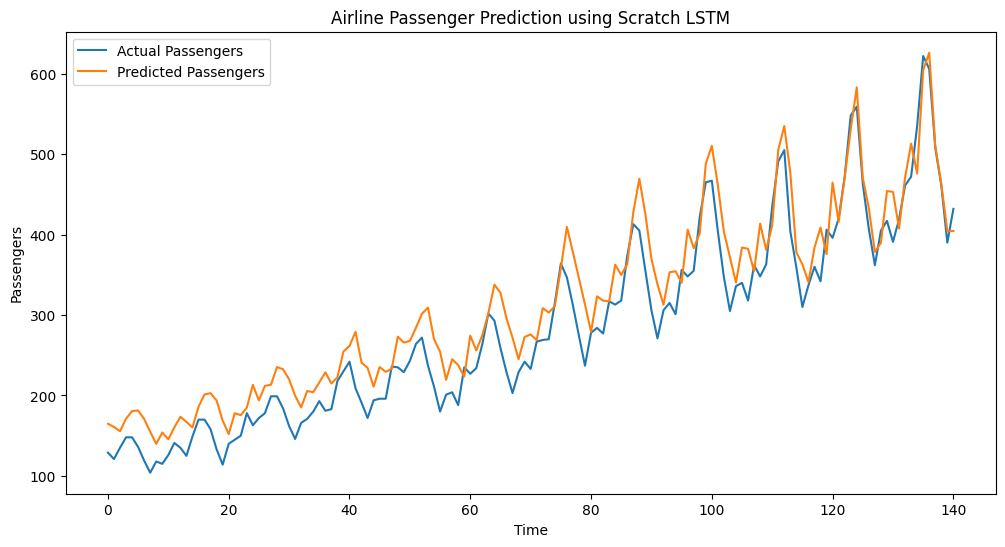

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,6))

plt.plot(actual, label="Actual Passengers")
plt.plot(predictions, label="Predicted Passengers")
plt.title("Airline Passenger Prediction using Scratch LSTM")
plt.xlabel("Time")
plt.ylabel("Passengers")
plt.legend()
plt.show()